### 04 eval on the fixed split
reads: prep/, ckpt/  
writes: results/metrics_*.csv, summary.csv, training_curves.png  
note: ht numbers here use all 24835 pairs and raw ranking, report the ht numbers from 05_cv instead

#### setup

In [1]:
import os, json, numpy as np, pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import average_precision_score

PREP = 'C:/Users/Nimishavarma/OneDrive/Dokumenty/hti-project/prep'
CKPT = 'C:/Users/Nimishavarma/OneDrive/Dokumenty/hti-project/ckpt'
OUT  = 'C:/Users/Nimishavarma/OneDrive/Dokumenty/hti-project/results'
os.makedirs(OUT, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#### load prep data

In [2]:
meta = json.load(open(f'{PREP}/meta.json'))
n_h, n_c, n_t = meta['n_h'], meta['n_c'], meta['n_t']

C_feat = torch.from_numpy(np.load(f'{PREP}/C_feat.npy')).to(device)
T_feat = torch.from_numpy(np.load(f'{PREP}/T_feat.npy')).to(device)

hc = np.load(f'{PREP}/hc_edges.npy')

# edge hiding data
ct_tr = np.load(f'{PREP}/ct_train.npy')
ct_tp = np.load(f'{PREP}/ct_test_pos.npy')
ct_tn = np.load(f'{PREP}/ct_test_neg.npy')
ht_pairs = np.load(f'{PREP}/ht_pairs.npy')

# compound disjoint data
ct_tr_cd = np.load(f'{PREP}/ct_train_cd.npy')
ct_tp_cd = np.load(f'{PREP}/ct_test_pos_cd.npy')
ct_tn_cd = np.load(f'{PREP}/ct_test_neg_cd.npy')

#### model classes

In [3]:
class RelConv(nn.Module):
    def __init__(self, in_dim, out_dim, n_rel):
        super().__init__()
        self.W_rel  = nn.Parameter(torch.randn(n_rel, in_dim, out_dim) * 0.01)
        self.W_self = nn.Parameter(torch.randn(in_dim, out_dim) * 0.01)
        self.bias   = nn.Parameter(torch.zeros(out_dim))
    def forward(self, x, edge_sets):
        out = x @ self.W_self
        for r, (src, dst) in enumerate(edge_sets):
            if src.numel() == 0: continue
            m = x[src] @ self.W_rel[r]
            agg = torch.zeros(x.size(0), out.size(1), device=x.device, dtype=out.dtype)
            agg.index_add_(0, dst, m)
            deg = torch.zeros(x.size(0), device=x.device)
            deg.index_add_(0, dst, torch.ones_like(dst, dtype=torch.float))
            out = out + agg / deg.clamp(min=1).unsqueeze(1)
        return out + self.bias

class Encoder(nn.Module):
    def __init__(self, n_h, n_c, n_t, d_in_c, d_in_t, d=128, n_rel=4, dropout=0.0):
        super().__init__()
        self.herb_emb = nn.Embedding(n_h, d)
        self.proj_c = nn.Linear(d_in_c, d)
        self.proj_t = nn.Linear(d_in_t, d)
        self.l1 = RelConv(d, d, n_rel)
        self.l2 = RelConv(d, d, n_rel)
        self.drop = nn.Dropout(dropout)
        self.n_h, self.n_c, self.n_t = n_h, n_c, n_t
    def project(self, Cf, Tf):
        return torch.cat([self.herb_emb.weight, F.relu(self.proj_c(Cf)), F.relu(self.proj_t(Tf))], dim=0)
    def forward(self, Cf, Tf, edge_sets):
        x = self.project(Cf, Tf)
        x = F.relu(self.l1(x, edge_sets))
        return self.l2(x, edge_sets)

class DistMult(nn.Module):
    def __init__(self, d, n_rel=1):
        super().__init__()
        self.rel = nn.Parameter(torch.randn(n_rel, d) * 0.01)
    def forward(self, hs, ht, r=0):
        return (hs * self.rel[r] * ht).sum(dim=-1)

class Model(nn.Module):
    def __init__(self, n_h, n_c, n_t, d_in_c, d_in_t, d=128):
        super().__init__()
        self.enc = Encoder(n_h, n_c, n_t, d_in_c, d_in_t, d=d, n_rel=4)
        self.dec = DistMult(d, n_rel=1)
    def encode(self, Cf, Tf, esets):
        return self.enc(Cf, Tf, esets)
    def score_ct(self, Z, c_idx, t_idx):
        return self.dec(Z[self.enc.n_h + c_idx], Z[self.enc.n_h + self.enc.n_c + t_idx])
    def all_scores_for_compound(self, Z, c_idx):
        hc_vec = Z[self.enc.n_h + c_idx]
        all_t = Z[self.enc.n_h + self.enc.n_c:]
        return (hc_vec.unsqueeze(0) * self.dec.rel[0]).matmul(all_t.t()).squeeze(0)

#### edge hiding model + embeddings

In [4]:
model = Model(n_h, n_c, n_t, C_feat.shape[1], T_feat.shape[1], d=128).to(device)
model.load_state_dict(torch.load(f'{CKPT}/best.pt', map_location=device))
model.eval()

h_abs = torch.from_numpy(hc[0]).long().to(device)
c_abs_hc = torch.from_numpy(hc[1] + n_h).long().to(device)
c_abs_ct = torch.from_numpy(ct_tr[0] + n_h).long().to(device)
t_abs_ct = torch.from_numpy(ct_tr[1] + n_h + n_c).long().to(device)
esets = [(h_abs, c_abs_hc),(c_abs_hc, h_abs),(c_abs_ct, t_abs_ct),(t_abs_ct, c_abs_ct)]

with torch.no_grad():
    Z = model.encode(C_feat, T_feat, esets)
print('EH embeddings:', Z.shape)

EH embeddings: torch.Size([3722, 128])


#### metric helpers

In [5]:
def hits_mrr(ranks, ks=(10, 50)):
    r = np.asarray(ranks, dtype=np.float64)
    out = {f'Hits@{k}': float((r <= k).mean()) for k in ks}
    out['MRR'] = float((1.0 / r).mean())
    return out

def pr_auc(pos_scores, neg_scores):
    y = np.concatenate([np.ones_like(pos_scores), np.zeros_like(neg_scores)])
    s = np.concatenate([pos_scores, neg_scores])
    return float(average_precision_score(y, s))

#### edge hiding: compound-target eval

In [6]:
tp = torch.from_numpy(ct_tp).long().to(device)
tn = torch.from_numpy(ct_tn).long().to(device)

with torch.no_grad():
    sp = model.score_ct(Z, tp[0], tp[1]).cpu().numpy()
    sn = model.score_ct(Z, tn[0], tn[1]).cpu().numpy()
ct_prauc = pr_auc(sp, sn)
print('CT PR-AUC', ct_prauc)

# rank test positives against all targets for the same compound
ranks = []
with torch.no_grad():
    for i in range(tp.shape[1]):
        c = tp[0, i].item()
        true_t = tp[1, i].item()
        all_s = model.all_scores_for_compound(Z, torch.tensor(c, device=device))
        order = torch.argsort(all_s, descending=True)
        rank = (order == true_t).nonzero(as_tuple=True)[0].item() + 1
        ranks.append(rank)
ct_rank = hits_mrr(ranks)
print('CT ranks', ct_rank)

ct_metrics = {'PR_AUC': ct_prauc, **ct_rank}
pd.DataFrame([ct_metrics]).to_csv(f'{OUT}/metrics_ct.csv', index=False)

CT PR-AUC 0.13307112638721572
CT ranks {'Hits@10': 0.07384760112888053, 'Hits@50': 0.3231420507996237, 'MRR': 0.04048220138648216}


#### edge hiding: herb-target eval

In [7]:
# herb score for a target = max over its compounds
from collections import defaultdict

herb_cmps = defaultdict(list)
for h, c in hc.T:
    herb_cmps[int(h)].append(int(c))

ht_true = defaultdict(set)
for h, t in ht_pairs:
    ht_true[int(h)].add(int(t))

n_h_used = len([h for h in ht_true if herb_cmps[h]])
ranks_ht = []

with torch.no_grad():
    for h, true_set in ht_true.items():
        cs = herb_cmps.get(h, [])
        if not cs:
            continue
        c_idx = torch.tensor(cs, device=device)
        hc_vecs = Z[n_h + c_idx]
        all_t = Z[n_h + n_c:]
        rel = model.dec.rel[0]
        s_mat = (hc_vecs * rel).matmul(all_t.t())    # (|C_h|, n_t)
        herb_score = s_mat.max(dim=0).values         # (n_t,)
        order = torch.argsort(herb_score, descending=True).cpu().numpy()
        pos = {t: i+1 for i, t in enumerate(order)}
        for t in true_set:
            ranks_ht.append(pos[t])

ht_rank = hits_mrr(ranks_ht)
print('HT ranks', ht_rank, 'n_pairs', len(ranks_ht), 'herbs used', n_h_used)

pd.DataFrame([ht_rank]).to_csv(f'{OUT}/metrics_ht.csv', index=False)

HT ranks {'Hits@10': 0.02150191262331387, 'Hits@50': 0.10481175760016107, 'MRR': 0.013666465477495506} n_pairs 24835 herbs used 60


### compound disjoint eval

#### compound disjoint model + embeddings

In [8]:
model_cd = Model(n_h, n_c, n_t, C_feat.shape[1], T_feat.shape[1], d=128).to(device)
model_cd.load_state_dict(torch.load(f'{CKPT}/best_cd.pt', map_location=device))
model_cd.eval()

c_abs_ct_cd = torch.from_numpy(ct_tr_cd[0] + n_h).long().to(device)
t_abs_ct_cd = torch.from_numpy(ct_tr_cd[1] + n_h + n_c).long().to(device)
esets_cd = [(h_abs, c_abs_hc),(c_abs_hc, h_abs),(c_abs_ct_cd, t_abs_ct_cd),(t_abs_ct_cd, c_abs_ct_cd)]

with torch.no_grad():
    Z_cd = model_cd.encode(C_feat, T_feat, esets_cd)
print('CD embeddings:', Z_cd.shape)

CD embeddings: torch.Size([3722, 128])


#### compound disjoint: compound-target eval

In [9]:
tp_cd = torch.from_numpy(ct_tp_cd).long().to(device)
tn_cd = torch.from_numpy(ct_tn_cd).long().to(device)

with torch.no_grad():
    sp_cd = model_cd.score_ct(Z_cd, tp_cd[0], tp_cd[1]).cpu().numpy()
    sn_cd = model_cd.score_ct(Z_cd, tn_cd[0], tn_cd[1]).cpu().numpy()
cd_prauc = pr_auc(sp_cd, sn_cd)
print('CD PR-AUC', cd_prauc)

ranks_cd = []
with torch.no_grad():
    for i in range(tp_cd.shape[1]):
        c = tp_cd[0, i].item()
        true_t = tp_cd[1, i].item()
        all_s = model_cd.all_scores_for_compound(Z_cd, torch.tensor(c, device=device))
        order = torch.argsort(all_s, descending=True)
        rank = (order == true_t).nonzero(as_tuple=True)[0].item() + 1
        ranks_cd.append(rank)
cd_rank = hits_mrr(ranks_cd)
print('CD ranks', cd_rank)

cd_metrics = {'PR_AUC': cd_prauc, **cd_rank}
pd.DataFrame([cd_metrics]).to_csv(f'{OUT}/metrics_ct_cd.csv', index=False)

CD PR-AUC 0.05304965222984707
CD ranks {'Hits@10': 0.05303030303030303, 'Hits@50': 0.20944741532976827, 'MRR': 0.02933351314635903}


#### training curves

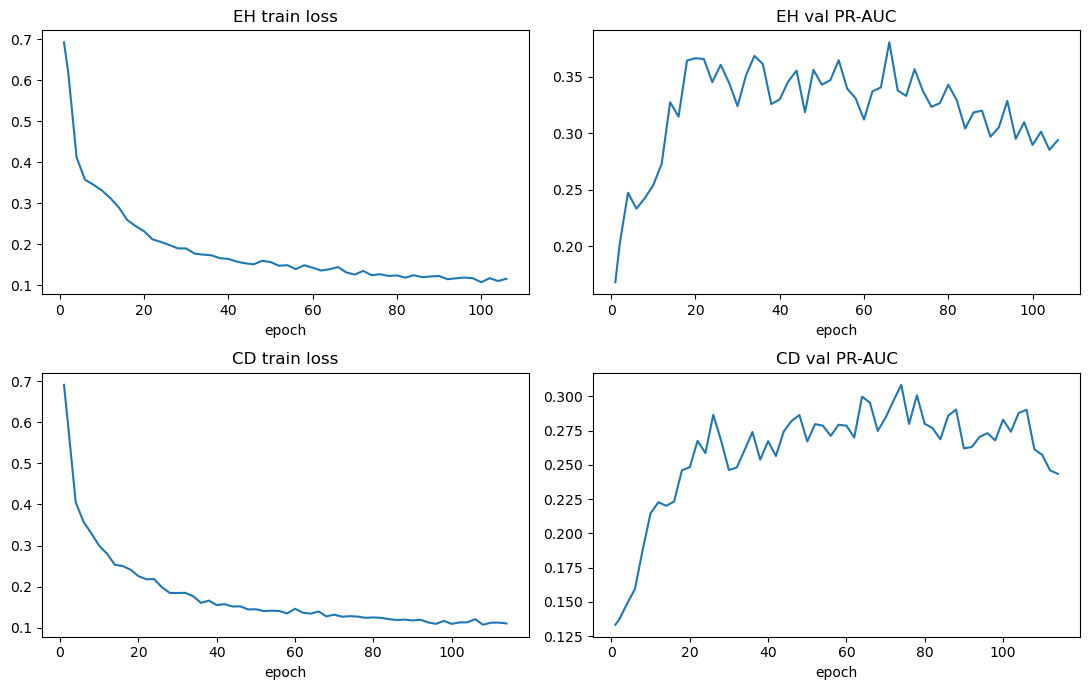

In [10]:
log_eh = pd.read_csv(f'{CKPT}/train_log.csv')
log_cd = pd.read_csv(f'{CKPT}/train_log_cd.csv')
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11,7))

axes[0,0].plot(log_eh['epoch'], log_eh['loss']); axes[0,0].set_title('EH train loss'); axes[0,0].set_xlabel('epoch')
axes[0,1].plot(log_eh['epoch'], log_eh['val_prauc']); axes[0,1].set_title('EH val PR-AUC'); axes[0,1].set_xlabel('epoch')
axes[1,0].plot(log_cd['epoch'], log_cd['loss']); axes[1,0].set_title('CD train loss'); axes[1,0].set_xlabel('epoch')
axes[1,1].plot(log_cd['epoch'], log_cd['val_prauc']); axes[1,1].set_title('CD val PR-AUC'); axes[1,1].set_xlabel('epoch')

fig.tight_layout()
fig.savefig(f'{OUT}/training_curves.png', dpi=120)
plt.show()

#### summary table

In [11]:
summary = pd.DataFrame({
    'split': ['edge_hiding']*7 + ['compound_disjoint']*4,
    'metric': [
        'CT PR-AUC','CT Hits@10','CT Hits@50','CT MRR',
        'HT Hits@10','HT Hits@50','HT MRR',
        'CT PR-AUC','CT Hits@10','CT Hits@50','CT MRR'
    ],
    'value': [
        ct_prauc, ct_rank['Hits@10'], ct_rank['Hits@50'], ct_rank['MRR'],
        ht_rank['Hits@10'], ht_rank['Hits@50'], ht_rank['MRR'],
        cd_prauc, cd_rank['Hits@10'], cd_rank['Hits@50'], cd_rank['MRR']
    ]
})
summary.to_csv(f'{OUT}/summary.csv', index=False)
print(summary)

                split      metric     value
0         edge_hiding   CT PR-AUC  0.133071
1         edge_hiding  CT Hits@10  0.073848
2         edge_hiding  CT Hits@50  0.323142
3         edge_hiding      CT MRR  0.040482
4         edge_hiding  HT Hits@10  0.021502
5         edge_hiding  HT Hits@50  0.104812
6         edge_hiding      HT MRR  0.013666
7   compound_disjoint   CT PR-AUC  0.053050
8   compound_disjoint  CT Hits@10  0.053030
9   compound_disjoint  CT Hits@50  0.209447
10  compound_disjoint      CT MRR  0.029334
